# Used-car marketplace: cleaning messy listings, modelling depreciation, and pricing vs time-to-sell
**Data.** 50,000 listings scraped from eBay Kleinanzeigen (Germany's classifieds site) in March-April 2016. The data are typical of real marketplaces: prices as text, German category labels, impossible registration years, €0 and €99,999,999 "prices", and a crawl that ends mid-life for many listings.

**Questions.**
1. What does a defensible, documented cleaning pipeline remove, and why?
2. How fast do cars lose value with age and mileage, and how does that differ by brand?
3. Do listings priced above what the model expects take longer to sell?

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import statsmodels.formula.api as smf
raw = pd.read_csv("data/ebay_used_cars_2016.csv.gz")
print(raw.shape); raw.head(3).T

(50000, 20)


,0,1,2
dateCrawled,2016-03-26 17:47:46,2016-04-04 13:38:56,2016-03-26 18:57:24
name,Peugeot_807_160_NAVTECH_ON_BOARD,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,Volkswagen_Golf_1.6_United
seller,privat,privat,privat
offerType,Angebot,Angebot,Angebot
price,"$5,000","$8,500","$8,990"
abtest,control,control,test
vehicleType,bus,limousine,limousine
yearOfRegistration,2004,1997,2009
gearbox,manuell,automatik,manuell
powerPS,158,286,102


In [2]:
df = raw.copy()
df.columns = ["date_crawled", "name", "seller", "offer_type", "price", "ab_test", "vehicle_type", "reg_year", "gearbox", "power_ps",
              "model", "odometer_km", "reg_month", "fuel", "brand", "unrepaired_damage", "ad_created", "n_pictures", "postal_code", "last_seen"]
df["price"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
df["odometer_km"] = df["odometer_km"].str.replace(r"[km,]", "", regex=True).astype(float)
tr = {"vehicle_type": {"limousine": "sedan", "kleinwagen": "small car", "kombi": "estate", "bus": "van", "cabrio": "convertible", "coupe": "coupe", "suv": "suv", "andere": "other"},
      "gearbox": {"manuell": "manual", "automatik": "automatic"}, "fuel": {"benzin": "petrol", "diesel": "diesel", "lpg": "lpg", "cng": "cng", "hybrid": "hybrid", "elektro": "electric", "andere": "other"},
      "unrepaired_damage": {"nein": "no", "ja": "yes"}, "seller": {"privat": "private", "gewerblich": "dealer"}, "offer_type": {"Angebot": "offer", "Gesuch": "wanted"}}
for c, mp in tr.items(): df[c] = df[c].map(mp)
for c in ["date_crawled", "ad_created", "last_seen"]: df[c] = pd.to_datetime(df[c])
print("constant / useless columns:", {c: df[c].nunique() for c in ["seller", "offer_type", "n_pictures"]})
df[["price", "odometer_km", "reg_year", "power_ps"]].describe(percentiles=[.01, .5, .99]).round(0)

constant / useless columns: {'seller': 2, 'offer_type': 2, 'n_pictures': 1}


,price,odometer_km,reg_year,power_ps
count,5.000e+04,50000.0,50000.0,50000.0
mean,9.840e+03,125733.0,2005.0,116.0
std,4.811e+05,40042.0,106.0,209.0
min,0.000e+00,5000.0,1000.0,0.0
1%,0.000e+00,5000.0,1978.0,0.0
50%,2.950e+03,150000.0,2003.0,105.0
99%,3.590e+04,150000.0,2018.0,344.0
max,1.000e+08,150000.0,9999.0,17700.0


In [3]:
rules = [("not a private sale offer", lambda d: (d.seller == "private") & (d.offer_type == "offer")),
         ("price outside €200-€150,000", lambda d: d.price.between(200, 150_000)),
         ("registration year after the crawl or before 1950", lambda d: d.reg_year.between(1950, 2016)),
         ("registered in 2016 after the listing was created", lambda d: ~((d.reg_year == 2016) & (d.reg_month > d.ad_created.dt.month))),
         ("power outside 30-500 PS", lambda d: d.power_ps.between(30, 500)),
         ("missing vehicle type, gearbox or fuel", lambda d: d[["vehicle_type", "gearbox", "fuel"]].notna().all(axis=1))]
audit, clean = [], df.copy()
for name, rule in rules:
    keep = rule(clean); audit.append({"rule": name, "removed": int((~keep).sum()), "remaining": int(keep.sum())}); clean = clean[keep]
clean = clean.drop(columns=["seller", "offer_type", "n_pictures", "ab_test"])
clean["unrepaired_damage"] = clean["unrepaired_damage"].fillna("unknown")
clean["age"] = 2016 - clean["reg_year"] + 0.5
pd.DataFrame(audit)

,rule,removed,remaining
0,not a private sale offer,2,49998
1,"price outside €200-€150,000",2373,47625
2,registration year after the crawl or before 1950,1876,45749
3,registered in 2016 after the listing was created,654,45095
4,power outside 30-500 PS,4158,40937
5,"missing vehicle type, gearbox or fuel",2804,38133


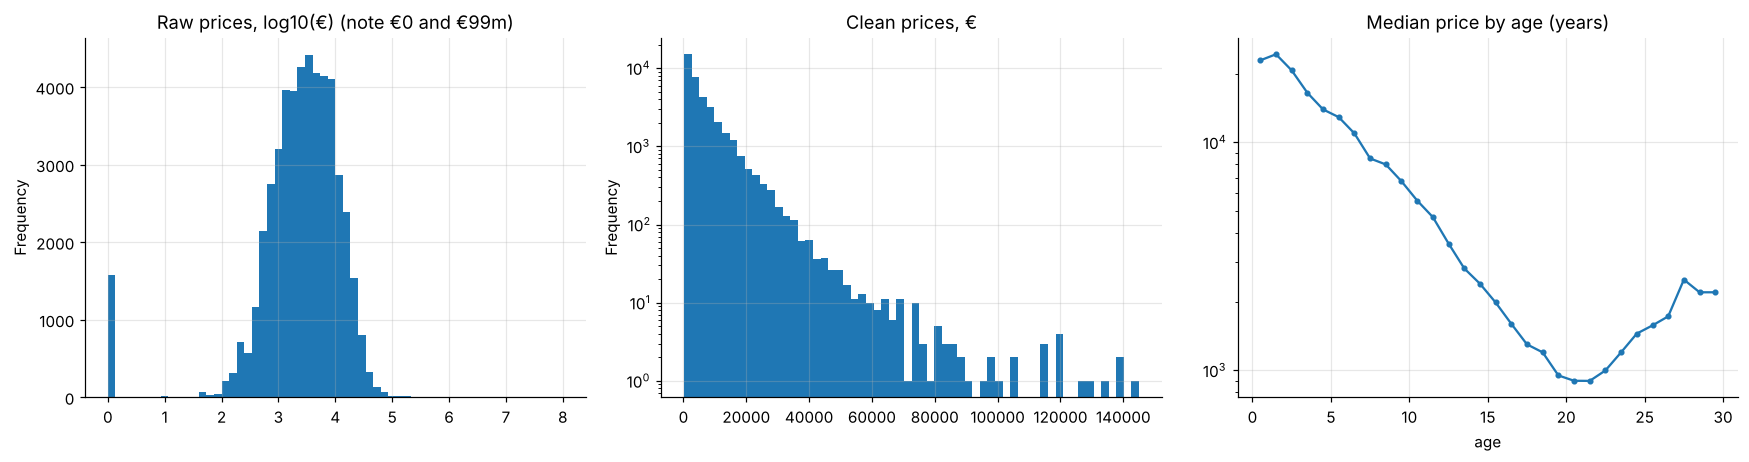

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
np.log10(raw["price"].str.replace(r"[$,]", "", regex=True).astype(float).clip(lower=1)).plot.hist(bins=60, ax=axes[0], title="Raw prices, log10(€) (note €0 and €99m)")
clean["price"].plot.hist(bins=60, ax=axes[1], logy=True, title="Clean prices, €")
clean.groupby("age")["price"].median().loc[:30].plot(ax=axes[2], marker=".", logy=True, title="Median price by age (years)")
plt.tight_layout(); plt.savefig(IMG / "cleaning.png", bbox_inches="tight"); plt.show()

## Depreciation model
$$\ln(\text{price}) = \beta_1\,\text{age} + \beta_2\,\text{age}^2 + \gamma\,\ln(\text{km}) + \text{brand}\times\text{age} + \text{type} + \text{fuel} + \text{gearbox} + \text{damage} + \varepsilon$$
Fitted on cars up to 25 years old (classics appreciate and would distort the curve). The brand × age interaction gives each brand its own depreciation rate.

In [5]:
m = clean[clean.age <= 25].copy()
top_brands = m.brand.value_counts().index[:12]
m["brand_g"] = np.where(m.brand.isin(top_brands), m.brand, "other")
fit = smf.ols("np.log(price) ~ age + I(age**2) + np.log(odometer_km) + C(brand_g, Treatment('volkswagen')) * age + C(vehicle_type) + C(fuel) + C(gearbox) + C(unrepaired_damage) + np.log(power_ps)", data=m).fit(cov_type="HC1")
print(f"n = {int(fit.nobs):,}, R² = {fit.rsquared:.3f}")
p = fit.params
eff = lambda k: 100 * (np.exp(p[k]) - 1)
print(f"unrepaired damage: {eff('C(unrepaired_damage)[T.yes]'):.0f}% | automatic premium over manual: {100 * (np.exp(-p['C(gearbox)[T.manual]']) - 1):.0f}%")
print(f"share of listings at the 150,000 km odometer cap: {(m.odometer_km == 150000).mean():.0%}")
print(f"+10% mileage: {100 * (1.1 ** p['np.log(odometer_km)'] - 1):.1f}% | +10% engine power: {100 * (1.1 ** p['np.log(power_ps)'] - 1):.1f}%")
rate = {}
for b in sorted(top_brands):
    slope = p["age"] + (p.get(f"C(brand_g, Treatment('volkswagen'))[T.{b}]:age", 0.0) if b != "volkswagen" else 0) + 2 * p["I(age ** 2)"] * 5
    rate[b] = 100 * (1 - np.exp(slope))
dep = pd.Series(rate, name="annual value loss at age 5, %").sort_values()
dep.round(1).to_frame()

n = 36,805, R² = 0.833
unrepaired damage: -44% | automatic premium over manual: 7%
share of listings at the 150,000 km odometer cap: 63%
+10% mileage: -0.9% | +10% engine power: 8.6%


,"annual value loss at age 5, %"
volkswagen,13.5
skoda,13.6
mercedes_benz,14.0
seat,14.2
peugeot,14.3
mazda,14.4
renault,14.4
bmw,14.5
opel,14.8
audi,14.8


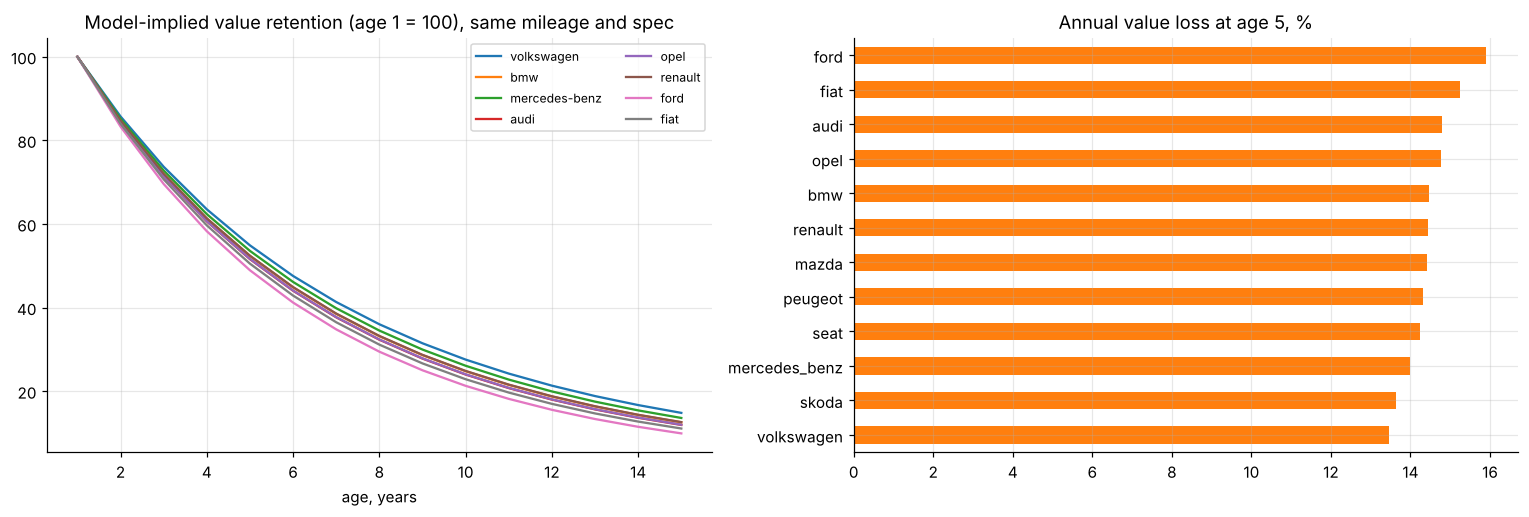

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ages = np.arange(1, 16)
for b in ["volkswagen", "bmw", "mercedes_benz", "audi", "opel", "renault", "ford", "fiat"]:
    sl = p.get(f"C(brand_g, Treatment('volkswagen'))[T.{b}]:age", 0.0) if b != "volkswagen" else 0.0
    curve = np.exp((p["age"] + sl) * ages + p["I(age ** 2)"] * ages ** 2)
    axes[0].plot(ages, 100 * curve / curve[0], label=b.replace("_", "-"))
axes[0].set_title("Model-implied value retention (age 1 = 100), same mileage and spec"); axes[0].set_xlabel("age, years"); axes[0].legend(fontsize=8, ncol=2)
dep.plot.barh(ax=axes[1], color="C1", title="Annual value loss at age 5, %")
plt.tight_layout(); plt.savefig(IMG / "depreciation.png", bbox_inches="tight"); plt.show()

## Does over-pricing slow the sale?
A listing whose `last_seen` timestamp falls well before the end of the crawl was taken down, which usually means sold. Listings still visible at the end are **censored**, so only ads created in the first half of the crawl are used, and "removed within 7 days" is the outcome. Price deviation is the residual from the depreciation model: positive means priced above comparable cars.

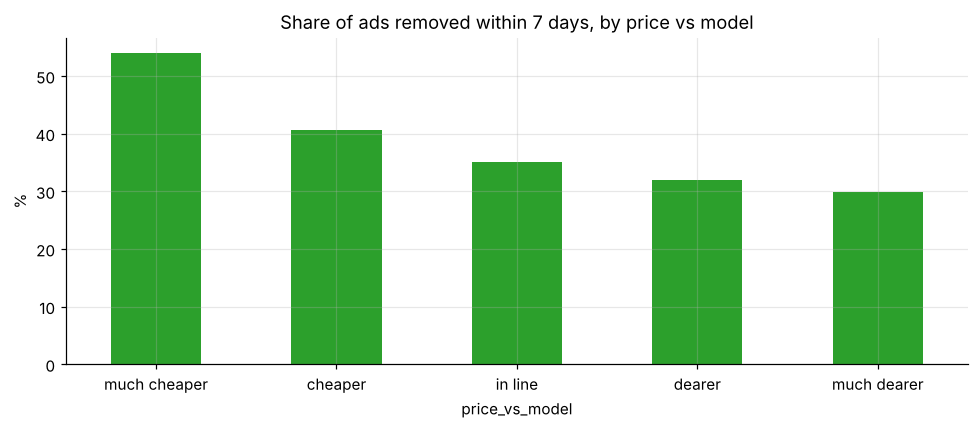

ads in window: 18,743 (created 05 Mar to 21 Mar); crawl ends 07 Apr 2016


,listings,removed_within_7d,median_price_gap_pct
price_vs_model,,,
much cheaper,3749,0.539,-42.649
cheaper,3748,0.406,-16.888
in line,3749,0.352,1.242
dearer,3748,0.319,21.586
much dearer,3749,0.298,61.362


In [7]:
crawl_end = clean.date_crawled.max().normalize()
m["resid"] = fit.resid
s = m[(m.ad_created >= "2016-03-05") & (m.ad_created <= crawl_end - pd.Timedelta(days=17))].copy()
s["days_listed"] = (s.last_seen - s.ad_created).dt.total_seconds() / 86400
s["gone_7d"] = s.days_listed <= 7
s["price_vs_model"] = pd.qcut(s.resid, 5, labels=["much cheaper", "cheaper", "in line", "dearer", "much dearer"])
g = s.groupby("price_vs_model", observed=True).agg(listings=("gone_7d", "size"), removed_within_7d=("gone_7d", "mean"),
                                                   median_price_gap_pct=("resid", lambda r: 100 * (np.exp(r.median()) - 1)))
ax = (100 * g["removed_within_7d"]).plot.bar(color="C2", rot=0, title="Share of ads removed within 7 days, by price vs model", figsize=(9, 4))
ax.set_ylabel("%"); plt.tight_layout(); plt.savefig(IMG / "time_to_sell.png", bbox_inches="tight"); plt.show()
print(f"ads in window: {len(s):,} (created {s.ad_created.min():%d %b} to {s.ad_created.max():%d %b}); crawl ends {crawl_end:%d %b %Y}")
g.round(3)

## Findings
* **Cleaning removed 24% of listings, every cut documented.** 50,000 raw ads became 38,133 usable ones. Prices of €0 or above €150k (2,373), impossible registration years such as 1000 or 9999 (1,876), registrations after the ad date (654), implausible engine power from 0 to 17,700 PS (4,158) and missing key attributes (2,804) were dropped. Three columns are constant and carry no information.
* **The depreciation model explains 83% of price variation** (log scale, 36,805 cars up to 25 years old). An unrepaired-damage flag cuts the price by 44%, automatics sell at a 7% premium, and +10% engine power adds about 8.6%.
* **Cars lose about 14-16% of their value per year at age 5.** Volkswagen (13.5%), Skoda and Mercedes-Benz hold value best; Ford (15.9%) and Fiat depreciate fastest. Median asking prices rise again after about 20 years as the market shifts to classics, which is why the model stops at 25.
* **Mileage looks weak (−0.9% per +10% km), but this is a data artefact:** 63% of listings sit at the site's 150,000 km cap, so the high-mileage range carries little information.
* **Price drives speed of sale.** Among 18,743 ads observed long enough, 54% of those priced well below comparable cars (median 43% under) were taken down within a week, against 30% of those priced well above (median 61% over). That is a direct, quantified pricing-vs-liquidity trade-off for sellers and dealers.